# Practical 8–9 — Sequence Models and Biological Foundation Models

**Machine Learning for Bioinformatics**

## Main biological task

Protein subcellular-localization prediction as a multi-label classification problem.

The same prediction problem will be approached using three levels of representation learning:


RNN/LSTM trained from scratch

frozen protein-language-model embeddings

GPU fine-tuning of a pretrained protein model

The practical is intentionally split into two computational environments:

### Local computer
- explore protein sequences and labels;
- manually tokenize amino-acid sequences;
- train a small RNN;
- train a small LSTM / BiLSTM;
- generate a small number of ESM-2 embeddings;
- train classifiers on frozen embeddings;
- compare representations.

### GPU server
- verify GPU availability;
- launch a proper training job;
- fine-tune a small pretrained ESM-2 model;
- save checkpoints and metrics;
- optionally compare partial/full fine-tuning or PEFT.

The GPU server is used **only where the additional compute is scientifically justified**.

## Learning objectives

By the end of the practical, students should be able to:

1. represent a biological sequence as tokens and tensors;
2. handle variable sequence length using padding and masks;
3. build and train a simple recurrent classifier;
4. explain the difference between RNN, LSTM and bidirectional LSTM;
5. obtain contextual protein embeddings from a pretrained model;
6. distinguish frozen-feature extraction from model fine-tuning;
7. use homology-aware train/validation/test partitions rather than naive random splitting;
8. launch a GPU training job on a remote server;
9. save and reload checkpoints and metrics;
10. compare predictive performance with computational cost.

# Part 0 — Environment

In [2]:
from pathlib import Path
import os
import json
import time
import random
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

RANDOM_STATE = 281026

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.11.0+cu128
Device: cuda


## 15. Connect to `vcc-server-kse`

This opens an SSH session to the course GPU machine. The alias stores the host address, username and key path in the local SSH configuration, so the private key is not placed in the notebook or repository.

Run in a terminal, not inside this notebook:

```bash
ssh vcc-server-kse
```

Check GPU visibility:

```bash
nvidia-smi
```

The recommended environment is a project-local `uv` environment. 

The CUDA check confirms that PyTorch can see the NVIDIA device. If it prints `False`, stop before starting training: check `nvidia-smi`, the installed PyTorch wheel and the driver.

After setup, work from the project directory:

```bash
cd ~/kse-week8
source .venv/bin/activate
.venv/bin/python -c "import torch; print(torch.cuda.is_available())"
```

# Part I — Dataset

## dataset structure

This practical uses the SwissProt and HPA tables. Each protein may have more than one localization label, so this is a multi-label classification task.

| column | meaning |
|---|---|
| `ACC` / `sid` | protein identifier in the SwissProt / HPA table |
| `Sequence` / `fasta` | amino-acid sequence |
| localization columns | binary labels; several can be 1 for one protein |
| `Partition` | predefined SwissProt partition used for train/validation |

The eight labels shared by both files are:

- Cytoplasm, Nucleus, Cell membrane, Mitochondrion
- Endoplasmic reticulum, Lysosome/Vacuole, Golgi apparatus, Peroxisome



In [3]:
DATA_DIR = next(
    folder for folder in (Path('.'), Path('week8'), Path('kse-github/practicals/week8'))
    if (folder / 'Swissprot_Train_Validation_dataset.csv').exists()
)
TRAIN_VAL_PATH = DATA_DIR / 'Swissprot_Train_Validation_dataset.csv'
HPA_TEST_PATH = DATA_DIR / 'hpa_testset.csv'

swissprot_raw = pd.read_csv(TRAIN_VAL_PATH)
hpa_raw = pd.read_csv(HPA_TEST_PATH)

# Use labels present in both files so the external test has the same target space.
TARGET_COLUMNS = [
    'Cytoplasm', 'Nucleus', 'Cell membrane', 'Mitochondrion',
    'Endoplasmic reticulum', 'Lysosome/Vacuole', 'Golgi apparatus',
    'Peroxisome',
]

df = swissprot_raw.rename(columns={'ACC': 'protein_id', 'Sequence': 'sequence', 'Partition': 'partition'}).copy()
hpa_df = hpa_raw.rename(columns={'sid': 'protein_id', 'fasta': 'sequence'}).copy()
print('SwissProt:', df.shape, '| HPA:', hpa_df.shape)

SwissProt: (28303, 16) | HPA: (1717, 11)


## 1. Basic dataset inspection

In [4]:

df


,Unnamed: 0,protein_id,Kingdom,partition,Membrane,Cytoplasm,Nucleus,Extracellular,Cell membrane,Mitochondrion,Plastid,Endoplasmic reticulum,Lysosome/Vacuole,Golgi apparatus,Peroxisome,sequence
0,0,Q28165,Metazoa,4,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...
1,1,Q86U42,Metazoa,4,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...
2,2,Q0GA42,Metazoa,3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAALGVRLRDCCSRGAVLLLFFSLSPRPPAAAAWLLGLR...
3,3,P82349,Metazoa,1,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAATEQQGSNGPVKKSMREKAVERRNVNKEHNSNFKAGY...
4,4,Q7L5N1,Metazoa,1,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAATNGTGGSSGMEVDAAVVPSVMACGVTGSVSVALHPL...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28298,28298,Q09712,Fungi,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,MYYIGHPSYYRKHIEHVCFQHSGILKKRNYQKNQKKYIMKLNESAM...
28299,28299,Q9V3C5,Metazoa,2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,MYYPVGWPKRVGLALPGESASIRHICCDAVKILVAAVGDDFLGIWY...
28300,28300,Q9SQQ9,Viridiplantae,4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MYYQNQHQGKNILSSSRMHITSERHPFLRGNSPGDSGLILSTDAKP...
28301,28301,Q9SQQ9-3,Viridiplantae,4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MYYQNQHQGKNILSSSRMHITSERHPFLRGNSPGDSGLILSTDAKP...


In [5]:
print('Partition counts:', df['partition'].value_counts().sort_index().to_dict())


Partition counts: {0: 5963, 1: 5451, 2: 5731, 3: 5696, 4: 5462}


In [6]:
print('Missing values:', int(df.isna().sum().sum()))


Missing values: 0


In [7]:

print('Labels per protein:', df[TARGET_COLUMNS].sum(axis=1).value_counts().sort_index().to_dict())
print('Sequence lengths:\n', df['sequence'].str.len().describe())

Labels per protein: {0.0: 3876, 1.0: 18090, 2.0: 5615, 3.0: 601, 4.0: 102, 5.0: 19}
Sequence lengths:
 count    28303.000000
mean       556.901141
std        558.491431
min         40.000000
25%        261.000000
50%        433.000000
75%        681.000000
max      34350.000000
Name: sequence, dtype: float64


## 2. Sequence-length distribution

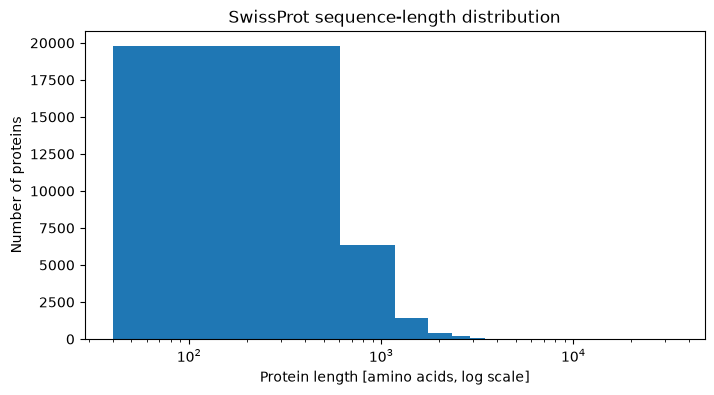

Longer than 300: 69.4%
Longer than 500: 41.3%
Longer than 1000: 11.3%


In [8]:
lengths = df['sequence'].str.len()

plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=60)
plt.xscale('log')
plt.xlabel('Protein length [amino acids, log scale]')
plt.ylabel('Number of proteins')
plt.title('SwissProt sequence-length distribution')
plt.show()

for limit in (300, 500, 1000):
    print(f'Longer than {limit}: {(lengths > limit).mean():.1%}')

### Questions

- Are protein lengths strongly skewed?
- What fraction of sequences would be truncated if we used a maximum length of 300, 500 or 1000 aa?
- Could sequence length itself correlate with the target?
- Why might truncation affect some localization classes more than others?

## 3. Class distribution

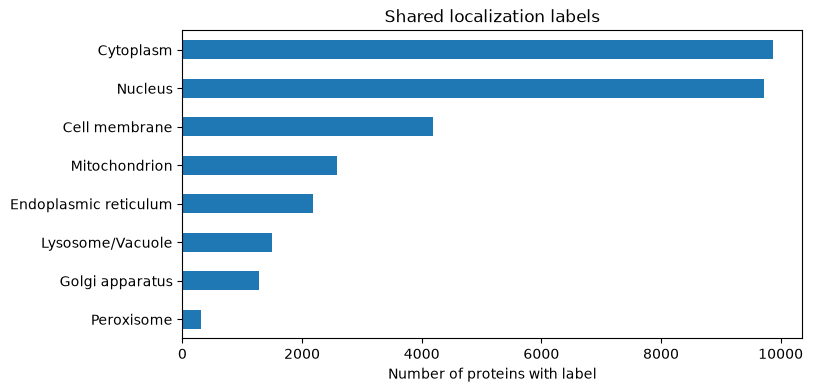

In [8]:
label_counts = df[TARGET_COLUMNS].sum().sort_values()
label_counts.plot(kind='barh', figsize=(8, 4))
plt.xlabel('Number of proteins with label')
plt.title('Shared localization labels')
plt.show()

# Part II — Why the split matters

For proteins, a random split can place close homologs into both train and test sets. Here the SwissProt table already provides five partitions, so we use them directly.

That can produce an overly optimistic estimate of generalization.

Conceptually:

\[
\text{patient-level split}
\quad\leftrightarrow\quad
\text{image-level split}
\quad\leftrightarrow\quad
\text{protein homology-aware split}
\]

The statistical principle is the same: strongly related observations should not be divided across training and evaluation sets. The HPA table is retained as an independent external test set.

In [9]:
train_df = df[df['partition'].isin([0, 1, 2, 3])].copy()
val_df = df[df['partition'] == 4].copy()


In [10]:
# A zero here would mean only an excluded localization label was present.
train_df = train_df[train_df[TARGET_COLUMNS].sum(axis=1) > 0].reset_index(drop=True)
val_df = val_df[val_df[TARGET_COLUMNS].sum(axis=1) > 0].reset_index(drop=True)
test_df = hpa_df.reset_index(drop=True)

print('Train:', len(train_df), '| validation:', len(val_df), '| HPA test:', len(test_df))
print('Test labels available:', [c for c in TARGET_COLUMNS if c in test_df.columns])

Train: 19708 | validation: 4719 | HPA test: 1717
Test labels available: ['Cytoplasm', 'Nucleus', 'Cell membrane', 'Mitochondrion', 'Endoplasmic reticulum', 'Lysosome/Vacuole', 'Golgi apparatus', 'Peroxisome']


# Part III — Manual amino-acid tokenization

Before using a foundation-model tokenizer, build a simple tokenizer manually.

This makes the sequence representation explicit.

In [11]:
AMINO_ACIDS = list("ACDEFGHIKLMNPQRSTVWY")

PAD_TOKEN = "<PAD>" #to unify size
UNK_TOKEN = "<UNK>" #to indicate new

VOCAB = [PAD_TOKEN, UNK_TOKEN] + AMINO_ACIDS

aa_to_idx = {aa: i for i, aa in enumerate(VOCAB)}
idx_to_aa = {i: aa for aa, i in aa_to_idx.items()}

print("Vocabulary size:", len(VOCAB))
print(aa_to_idx)

Vocabulary size: 22
{'<PAD>': 0, '<UNK>': 1, 'A': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7, 'H': 8, 'I': 9, 'K': 10, 'L': 11, 'M': 12, 'N': 13, 'P': 14, 'Q': 15, 'R': 16, 'S': 17, 'T': 18, 'V': 19, 'W': 20, 'Y': 21}


## 4. Tokenize one sequence

In [12]:
def encode_sequence(sequence):
    return [
        aa_to_idx.get(aa, aa_to_idx[UNK_TOKEN])
        for aa in sequence
    ]

example_sequence = "MKWVTFISLL"

print(example_sequence)
print(encode_sequence(example_sequence))

MKWVTFISLL
[12, 10, 20, 19, 18, 6, 9, 17, 11, 11]


## 5. Padding and truncation

Neural-network batches require tensors with compatible shapes.

For this practical we will use:

\[
L_{\max} = \text{MAX_LEN}
\]

Shorter sequences are padded; longer sequences are truncated.

We also create a mask so that the model can distinguish real residues from padding.

In [13]:
MAX_LEN = 15

def encode_and_pad(sequence, max_len=MAX_LEN):
    ids = encode_sequence(sequence)

    ids = ids[:max_len]
    length = len(ids)

    padded = ids + [aa_to_idx[PAD_TOKEN]] * (max_len - length)
    mask = [1] * length + [0] * (max_len - length)

    return (
        torch.tensor(padded, dtype=torch.long),
        torch.tensor(mask, dtype=torch.bool),
        length
    )

ids, mask, length = encode_and_pad(example_sequence)

print(ids.shape)
print(mask.shape)
print("Original length:", length)

torch.Size([15])
torch.Size([15])
Original length: 10


In [14]:
mask

tensor([ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
        False, False, False, False, False])

In [15]:
ids

tensor([12, 10, 20, 19, 18,  6,  9, 17, 11, 11,  0,  0,  0,  0,  0])

### Discussion

Questions:

- What information might be lost by truncation?
- Is the N-terminus particularly important for localization?
- Would C-terminal signals also matter?
- Would random cropping make biological sense here?

# Part IV — Dataset and DataLoader

In [16]:
class ProteinSequenceDataset(Dataset):
    def __init__(self, dataframe, label_columns, max_len=1000):
        self.df = dataframe.reset_index(drop=True)
        self.label_columns = label_columns
        self.max_len = max_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        ids, mask, length = encode_and_pad(row['sequence'], self.max_len)

        # A protein can have several positive localization labels.
        y = torch.tensor(row[self.label_columns].to_numpy(dtype=np.float32))
        return {
            'input_ids': ids,
            'attention_mask': mask,
            'length': length,
            'label': y,
            'protein_id': row['protein_id'],
        }

In [17]:
# Keep only target columns shared by the two datasets.
label_columns = [c for c in TARGET_COLUMNS if c in train_df.columns and c in test_df.columns]

train_ds = ProteinSequenceDataset(train_df, label_columns, MAX_LEN)
val_ds = ProteinSequenceDataset(val_df, label_columns, MAX_LEN)
test_ds = ProteinSequenceDataset(test_df, label_columns, MAX_LEN)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=128, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)
print('Labels used:', label_columns)

Labels used: ['Cytoplasm', 'Nucleus', 'Cell membrane', 'Mitochondrion', 'Endoplasmic reticulum', 'Lysosome/Vacuole', 'Golgi apparatus', 'Peroxisome']


# Part V — Baseline recurrent neural network

Architecture:

\[
\text{token IDs}

\rightarrow
\text{Embedding}

\rightarrow
\text{RNN}

\rightarrow
\text{sequence representation}

\rightarrow
\text{Linear multi-label classifier}
\]

In [18]:
class RNNClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        n_classes,
        pad_idx=0
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_idx
        )

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, input_ids, attention_mask=None):
        x = self.embedding(input_ids)

        _, h_n = self.rnn(x)

        h_last = h_n[-1]

        return self.classifier(h_last)

In [19]:
rnn_model = RNNClassifier(
    vocab_size=len(VOCAB),
    embedding_dim=64,
    hidden_dim=128,
    n_classes=len(label_columns),
    pad_idx=aa_to_idx[PAD_TOKEN],
).to(DEVICE)

print(rnn_model)
print('Trainable parameters:', count_trainable_parameters(rnn_model) if 'count_trainable_parameters' in globals() else 'see next cell')

RNNClassifier(
  (embedding): Embedding(22, 64, padding_idx=0)
  (rnn): RNN(64, 128, batch_first=True)
  (classifier): Linear(in_features=128, out_features=8, bias=True)
)
Trainable parameters: see next cell


## 6. Count trainable parameters

In [20]:
def count_trainable_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

print(count_trainable_parameters(rnn_model))

27272


# Part VI — Training utilities

In [22]:
def multilabel_metrics(y_true, logits, threshold=0.5):
    # Each output is an independent label probability.
    y_pred = (1 / (1 + np.exp(-logits)) >= threshold).astype(int)
    return {
        'exact_match': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'micro_f1': f1_score(y_true, y_pred, average='micro', zero_division=0),
        'y_true': y_true,
        'y_pred': y_pred,
    }

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, y_true, logits_all = 0.0, [], []

    for batch in loader:
        ids = batch['input_ids'].to(device)
        mask = batch['attention_mask'].to(device)
        y = batch['label'].to(device)
        optimizer.zero_grad()
        logits = model(ids, mask)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * y.size(0)
        y_true.append(y.detach().cpu().numpy())
        logits_all.append(logits.detach().cpu().numpy())

    metrics = multilabel_metrics(np.vstack(y_true), np.vstack(logits_all))
    metrics['loss'] = total_loss / len(loader.dataset)
    return metrics

In [23]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, y_true, logits_all = 0.0, [], []

    for batch in loader:
        ids = batch['input_ids'].to(device)
        mask = batch['attention_mask'].to(device)
        y = batch['label'].to(device)
        logits = model(ids, mask)
        total_loss += criterion(logits, y).item() * y.size(0)
        y_true.append(y.cpu().numpy())
        logits_all.append(logits.cpu().numpy())

    metrics = multilabel_metrics(np.vstack(y_true), np.vstack(logits_all))
    metrics['loss'] = total_loss / len(loader.dataset)
    return metrics

## 7. Train the RNN baseline

After training, the next code cell uses `torchview` to display the computational graph and tensor shapes.

In [ ]:
# BCEWithLogitsLoss is appropriate because every localization is a separate label.
positive = train_df[label_columns].sum().to_numpy()
pos_weight = (len(train_df) - positive) / (positive + 1e-6)
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, dtype=torch.float32, device=DEVICE))

def fit_model(model, epochs=5):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    for epoch in range(1, epochs + 1):
        train_metrics = train_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_metrics = evaluate(model, val_loader, criterion, DEVICE)
        history.append({
            'epoch': epoch,
            'train_loss': train_metrics['loss'],
            'val_loss': val_metrics['loss'],
            'train_macro_f1': train_metrics['macro_f1'],
            'val_macro_f1': val_metrics['macro_f1'],
            'val_micro_f1': val_metrics['micro_f1'],
        })
        print(f'{epoch:02d} | train F1={train_metrics["macro_f1"]:.3f} | val F1={val_metrics["macro_f1"]:.3f}')
    return pd.DataFrame(history)

history_rnn = fit_model(rnn_model)
test_metrics_rnn = evaluate(rnn_model, test_loader, criterion, DEVICE)
print('HPA test macro-F1:', round(test_metrics_rnn['macro_f1'], 3))

01 | train F1=0.272 | val F1=0.279
02 | train F1=0.294 | val F1=0.298
03 | train F1=0.303 | val F1=0.282
04 | train F1=0.308 | val F1=0.309
05 | train F1=0.316 | val F1=0.297
06 | train F1=0.319 | val F1=0.305
07 | train F1=0.324 | val F1=0.299
08 | train F1=0.327 | val F1=0.257
09 | train F1=0.334 | val F1=0.283
10 | train F1=0.340 | val F1=0.278
11 | train F1=0.347 | val F1=0.282
12 | train F1=0.357 | val F1=0.272
13 | train F1=0.371 | val F1=0.292
14 | train F1=0.363 | val F1=0.290
15 | train F1=0.386 | val F1=0.290
16 | train F1=0.398 | val F1=0.285
17 | train F1=0.410 | val F1=0.285
18 | train F1=0.415 | val F1=0.278
19 | train F1=0.427 | val F1=0.287
20 | train F1=0.435 | val F1=0.283
HPA test macro-F1: 0.253



(process:27620): Pango-WARNING **: 18:49:05.581: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


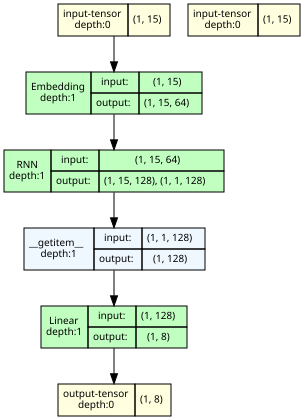

In [25]:
from IPython.display import display
from torchview import draw_graph

example_batch = next(iter(train_loader))
graph_inputs = (
    example_batch['input_ids'][:1].to(DEVICE),
    example_batch['attention_mask'][:1].to(DEVICE),
)

def show_model_graph(model, name):
    # One example exposes the architecture and tensor shapes.
    model.eval()
    graph = draw_graph(model, input_data=graph_inputs, graph_name=name, expand_nested=True, depth=4)
    display(graph.visual_graph)

show_model_graph(rnn_model, 'RNN_classifier')

## 8. Plot learning curves

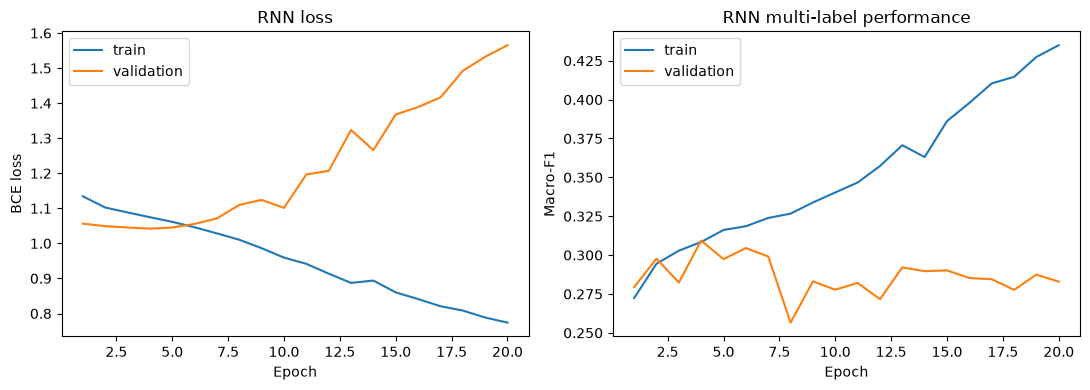

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_rnn['epoch'], history_rnn['train_loss'], label='train')
axes[0].plot(history_rnn['epoch'], history_rnn['val_loss'], label='validation')
axes[0].set(xlabel='Epoch', ylabel='BCE loss', title='RNN loss')
axes[0].legend()
axes[1].plot(history_rnn['epoch'], history_rnn['train_macro_f1'], label='train')
axes[1].plot(history_rnn['epoch'], history_rnn['val_macro_f1'], label='validation')
axes[1].set(xlabel='Epoch', ylabel='Macro-F1', title='RNN multi-label performance')
axes[1].legend()
plt.tight_layout()
plt.show()

# Part VII — LSTM

Swap the recurrent unit while leaving the rest of the problem unchanged.

\[
\text{Embedding}

\rightarrow
\text{LSTM}

\rightarrow
\text{classifier}
\]

In [27]:
class LSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        n_classes,
        pad_idx=0,
        bidirectional=False,
        num_layers=1,
        dropout=0.0
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_idx
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0
        )

        out_dim = hidden_dim * (2 if bidirectional else 1)

        self.classifier = nn.Linear(out_dim, n_classes)

        self.bidirectional = bidirectional

    def forward(self, input_ids, attention_mask=None):
        x = self.embedding(input_ids)

        _, (h_n, _) = self.lstm(x)

        if self.bidirectional:
            h_last = torch.cat(
                [h_n[-2], h_n[-1]],
                dim=1
            )
        else:
            h_last = h_n[-1]

        return self.classifier(h_last)

## 9. Train and compare

Recommended experiments:

1. vanilla RNN;
2. unidirectional LSTM;
3. bidirectional LSTM.

Keep the dataset, label order and validation split fixed. Because this is multi-label classification, compare macro-F1 rather than only exact-match accuracy.

In [28]:
lstm_model = LSTMClassifier(
    vocab_size=len(VOCAB),
    embedding_dim=64,
    hidden_dim=128,
    n_classes=len(label_columns),
    pad_idx=aa_to_idx[PAD_TOKEN],
).to(DEVICE)

bilstm_model = LSTMClassifier(
    vocab_size=len(VOCAB),
    embedding_dim=64,
    hidden_dim=128,
    n_classes=len(label_columns),
    pad_idx=aa_to_idx[PAD_TOKEN],
    bidirectional=True,
).to(DEVICE)

history_lstm = fit_model(lstm_model)
history_bilstm = fit_model(bilstm_model)
test_metrics_lstm = evaluate(lstm_model, test_loader, criterion, DEVICE)
test_metrics_bilstm = evaluate(bilstm_model, test_loader, criterion, DEVICE)

comparison = pd.DataFrame({
    'RNN': [count_trainable_parameters(rnn_model), test_metrics_rnn['macro_f1']],
    'LSTM': [count_trainable_parameters(lstm_model), test_metrics_lstm['macro_f1']],
    'BiLSTM': [count_trainable_parameters(bilstm_model), test_metrics_bilstm['macro_f1']],
}, index=['trainable_parameters', 'HPA_macro_f1']).T
display(comparison)

01 | train F1=0.291 | val F1=0.313
02 | train F1=0.320 | val F1=0.294
03 | train F1=0.325 | val F1=0.295
04 | train F1=0.329 | val F1=0.314
05 | train F1=0.338 | val F1=0.297
06 | train F1=0.342 | val F1=0.304
07 | train F1=0.354 | val F1=0.296
08 | train F1=0.365 | val F1=0.294
09 | train F1=0.381 | val F1=0.302
10 | train F1=0.398 | val F1=0.300
11 | train F1=0.417 | val F1=0.298
12 | train F1=0.438 | val F1=0.293
13 | train F1=0.458 | val F1=0.301
14 | train F1=0.481 | val F1=0.293
15 | train F1=0.499 | val F1=0.291
16 | train F1=0.519 | val F1=0.287
17 | train F1=0.542 | val F1=0.283
18 | train F1=0.572 | val F1=0.289
19 | train F1=0.585 | val F1=0.280
20 | train F1=0.610 | val F1=0.287
01 | train F1=0.291 | val F1=0.316
02 | train F1=0.322 | val F1=0.305
03 | train F1=0.329 | val F1=0.301
04 | train F1=0.336 | val F1=0.304
05 | train F1=0.346 | val F1=0.303
06 | train F1=0.357 | val F1=0.309
07 | train F1=0.376 | val F1=0.300
08 | train F1=0.406 | val F1=0.301
09 | train F1=0.441 

,trainable_parameters,HPA_macro_f1
RNN,27272.0,0.252594
LSTM,101768.0,0.247206
BiLSTM,202120.0,0.236846


## 10. Inspecting recurrent-model predictions

This is a **multi-label** problem: one protein can belong to several localization classes. Therefore, we draw one binary confusion matrix for each label instead of forcing the task into a single multiclass matrix. We also translate the binary predictions back into localization names.

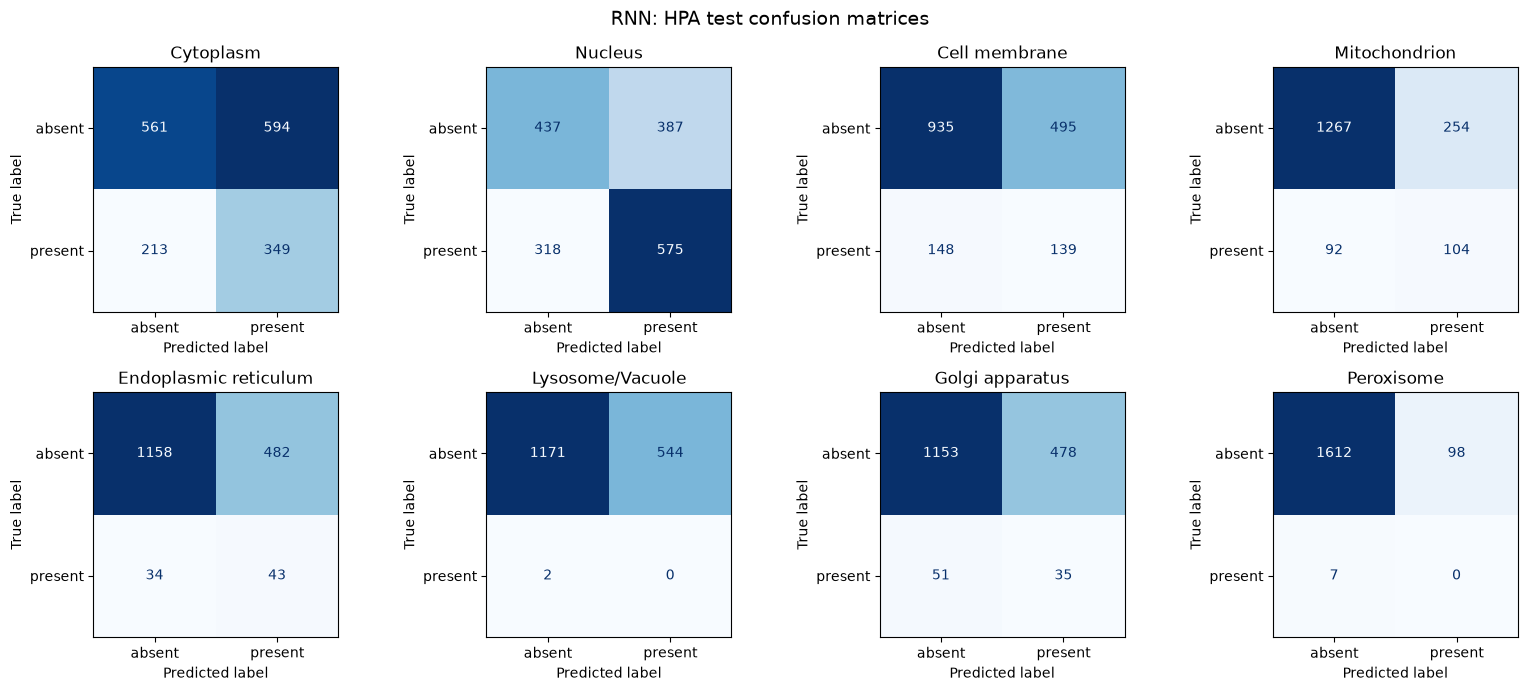

RNN: macro-F1 = 0.253


,protein_id,true_labels,predicted_labels,highest_probability
0,ENSP00000355743,Nucleus,Nucleus,0.717414
1,ENSP00000429628,Nucleus,Mitochondrion,0.573422
2,ENSP00000266544,Mitochondrion,"Mitochondrion, Golgi apparatus",0.894517
3,ENSP00000470652,Golgi apparatus,"Cell membrane, Golgi apparatus",0.661901
4,ENSP00000460751,Nucleus,"Lysosome/Vacuole, Golgi apparatus",0.770260
5,ENSP00000485945,Nucleus,"Cell membrane, Endoplasmic reticulum, Lysosome...",0.947321
6,ENSP00000472858,Nucleus,"Cytoplasm, Nucleus",0.702248
7,ENSP00000398124,Nucleus,"Cell membrane, Endoplasmic reticulum",0.621182
8,ENSP00000430889,"Nucleus, Cell membrane","Cytoplasm, Nucleus",0.645021
9,ENSP00000428877,"Nucleus, Cell membrane","Cytoplasm, Nucleus",0.645021


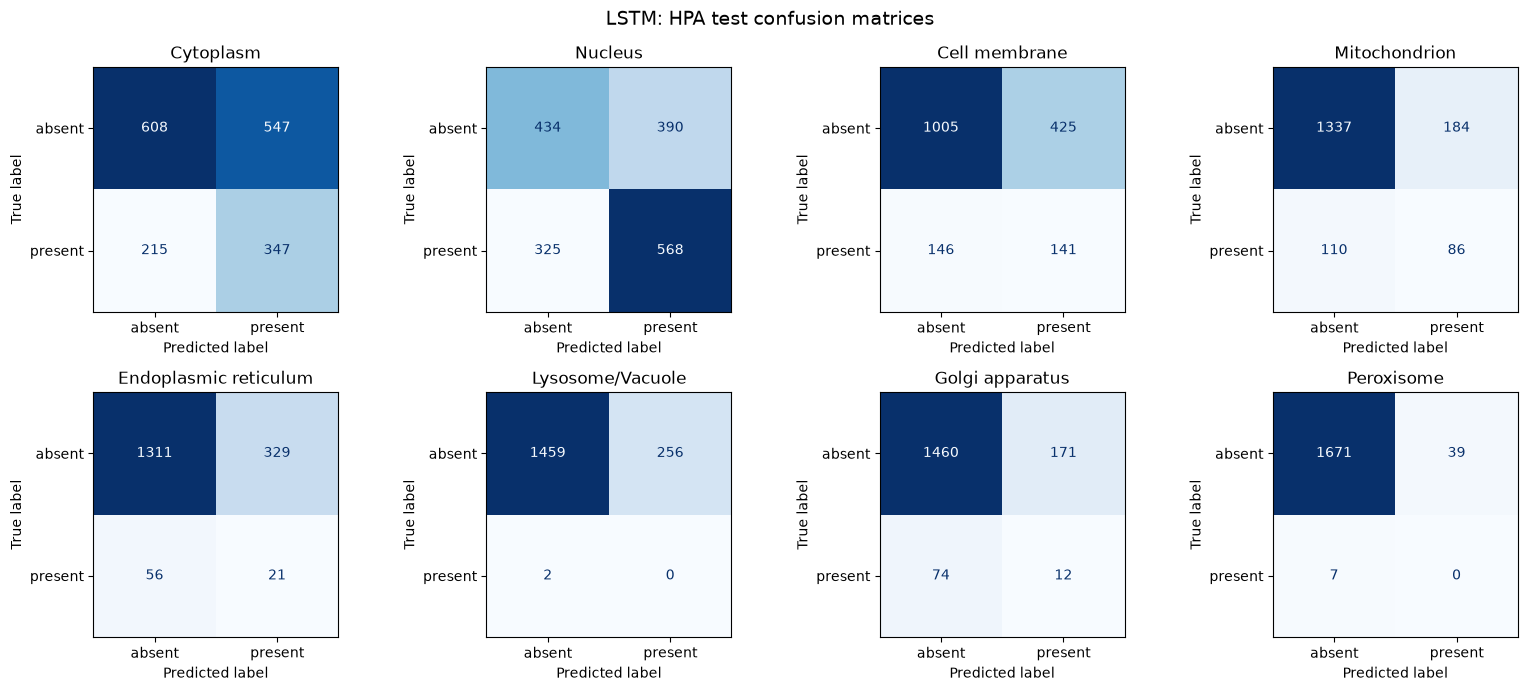

LSTM: macro-F1 = 0.247


,protein_id,true_labels,predicted_labels,highest_probability
0,ENSP00000355743,Nucleus,"Cell membrane, Mitochondrion, Lysosome/Vacuole",0.833236
1,ENSP00000429628,Nucleus,"Cytoplasm, Endoplasmic reticulum",0.614906
2,ENSP00000266544,Mitochondrion,"Endoplasmic reticulum, Lysosome/Vacuole, Golgi...",0.945031
3,ENSP00000470652,Golgi apparatus,"Cytoplasm, Cell membrane, Endoplasmic reticulu...",0.979723
4,ENSP00000460751,Nucleus,"Cytoplasm, Nucleus, Mitochondrion",0.576521
5,ENSP00000485945,Nucleus,"Cytoplasm, Nucleus, Endoplasmic reticulum",0.849242
6,ENSP00000472858,Nucleus,"Cytoplasm, Nucleus, Peroxisome",0.891590
7,ENSP00000398124,Nucleus,"Cytoplasm, Nucleus",0.738760
8,ENSP00000430889,"Nucleus, Cell membrane","Cytoplasm, Cell membrane, Lysosome/Vacuole",0.680837
9,ENSP00000428877,"Nucleus, Cell membrane","Cytoplasm, Cell membrane, Lysosome/Vacuole",0.680837


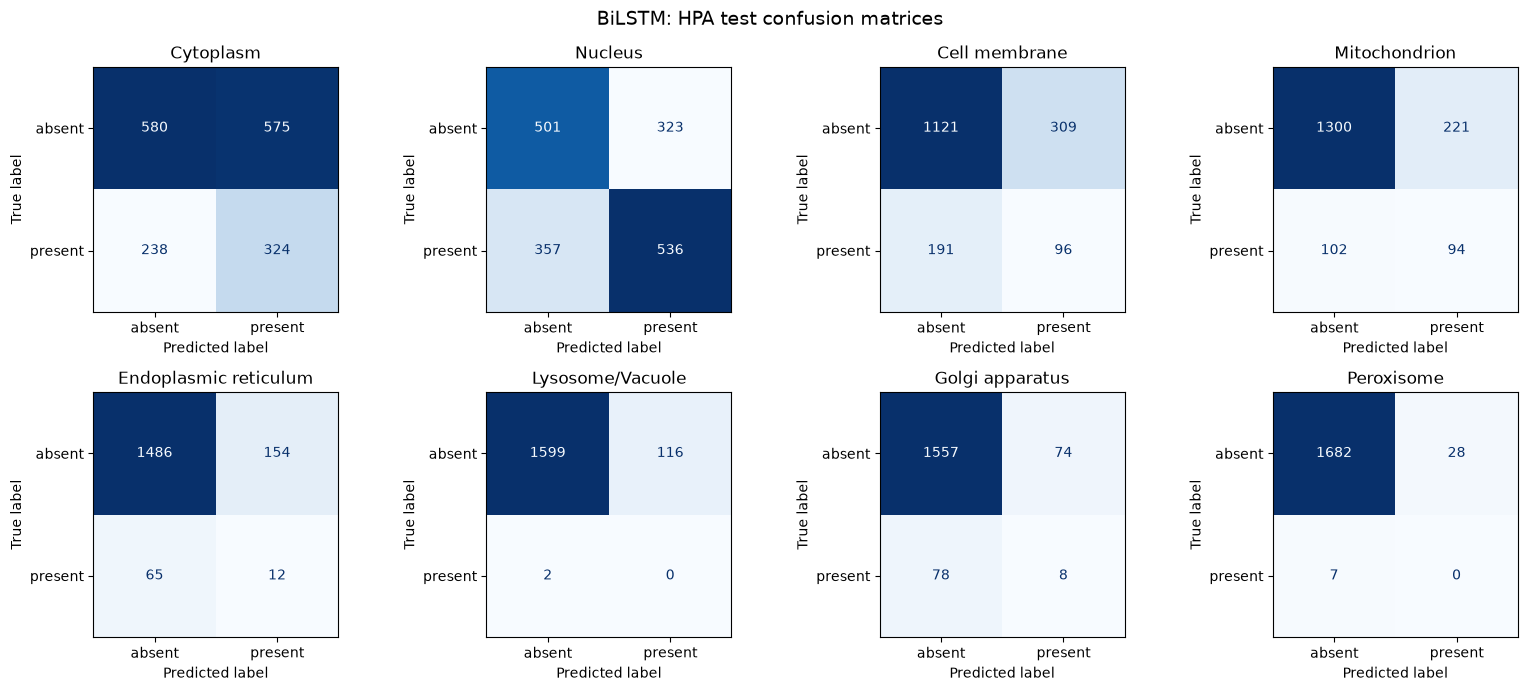

BiLSTM: macro-F1 = 0.237


,protein_id,true_labels,predicted_labels,highest_probability
0,ENSP00000355743,Nucleus,Lysosome/Vacuole,0.858327
1,ENSP00000429628,Nucleus,Nucleus,0.621990
2,ENSP00000266544,Mitochondrion,Mitochondrion,0.997985
3,ENSP00000470652,Golgi apparatus,"Cytoplasm, Nucleus",0.887843
4,ENSP00000460751,Nucleus,none,0.414339
5,ENSP00000485945,Nucleus,"Cytoplasm, Nucleus",0.870393
6,ENSP00000472858,Nucleus,"Cytoplasm, Nucleus",0.895979
7,ENSP00000398124,Nucleus,"Cytoplasm, Nucleus",0.638397
8,ENSP00000430889,"Nucleus, Cell membrane","Mitochondrion, Endoplasmic reticulum, Lysosome...",0.911895
9,ENSP00000428877,"Nucleus, Cell membrane","Mitochondrion, Endoplasmic reticulum, Lysosome...",0.911895


In [29]:
from sklearn.metrics import multilabel_confusion_matrix

def collect_logits(model, loader, device):
    model.eval()
    all_true, all_logits = [], []
    with torch.inference_mode():
        for batch in loader:
            inputs = batch['input_ids'].to(device)
            mask = batch['attention_mask'].to(device)
            all_true.append(batch['label'].cpu().numpy())
            all_logits.append(model(inputs, mask).cpu().numpy())
    return np.vstack(all_true), np.vstack(all_logits)

def plot_multilabel_confusions(y_true, y_pred, model_name):
    matrices = multilabel_confusion_matrix(y_true, y_pred)
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for label, matrix, ax in zip(label_columns, matrices, axes.ravel()):
        ConfusionMatrixDisplay(
            confusion_matrix=matrix, display_labels=['absent', 'present']
        ).plot(ax=ax, colorbar=False, cmap='Blues', values_format='d')
        ax.set_title(label)
    fig.suptitle(f'{model_name}: HPA test confusion matrices', fontsize=14)
    plt.tight_layout()
    plt.show()

def prediction_table(model, model_name, frame=test_df, loader=test_loader, threshold=0.5):
    y_true, logits = collect_logits(model, loader, DEVICE)
    probabilities = 1 / (1 + np.exp(-logits))
    y_pred = (probabilities >= threshold).astype(int)
    rows = []
    for i in range(len(y_true)):
        true_names = [label for label, value in zip(label_columns, y_true[i]) if value == 1]
        pred_names = [label for label, value in zip(label_columns, y_pred[i]) if value == 1]
        rows.append({
            'protein_id': frame.iloc[i]['protein_id'],
            'true_labels': ', '.join(true_names) or 'none',
            'predicted_labels': ', '.join(pred_names) or 'none',
            'highest_probability': probabilities[i].max(),
        })
    result = pd.DataFrame(rows)
    print(f'{model_name}: macro-F1 = {f1_score(y_true, y_pred, average="macro", zero_division=0):.3f}')
    return result

for model_name, model in [('RNN', rnn_model), ('LSTM', lstm_model), ('BiLSTM', bilstm_model)]:
    true_labels, model_logits = collect_logits(model, test_loader, DEVICE)
    model_predictions = (1 / (1 + np.exp(-model_logits)) >= 0.5).astype(int)
    plot_multilabel_confusions(true_labels, model_predictions, model_name)
    display(prediction_table(model, model_name).head(10))


(process:1584): Pango-WARNING **: 19:19:41.397: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


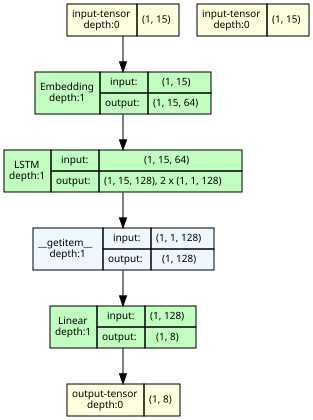


(process:23916): Pango-WARNING **: 19:19:41.447: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


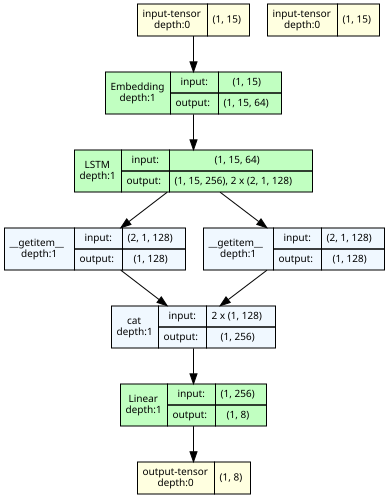

In [30]:

show_model_graph(lstm_model, 'LSTM_classifier')
show_model_graph(bilstm_model, 'BiLSTM_classifier')

### Results table

| Model | Trainable parameters | Val macro-F1 | Test macro-F1 | Training time |
|---|---:|---:|---:|---:|
| RNN | | | | |
| LSTM | | | | |
| BiLSTM | | | | |

# Part IX — Foundation model: ESM-2

Now move from a representation learned entirely from this small labeled dataset to a representation learned during large-scale pretraining.

For classroom use, start with a small checkpoint locally.

Suggested local model:

```text
facebook/esm2_t6_8M_UR50D
```

A larger checkpoint can be reserved for GPU-server fine-tuning.

In [31]:
from transformers import AutoTokenizer, AutoModel

LOCAL_ESM_MODEL = 'facebook/esm2_t6_8M_UR50D'
RUN_LOCAL_ESM = True  # Set True after installing transformers and downloading the checkpoint.

if RUN_LOCAL_ESM:
    esm_tokenizer = AutoTokenizer.from_pretrained(LOCAL_ESM_MODEL)
    esm_model = AutoModel.from_pretrained(LOCAL_ESM_MODEL).to(DEVICE)
    esm_model.eval()
    print('Loaded:', LOCAL_ESM_MODEL)
else:
    print('Local ESM loading is disabled; set RUN_LOCAL_ESM=True to run this section.')

W1028 19:26:14.831000 2496 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loaded: facebook/esm2_t6_8M_UR50D


## 10. Tokenize one protein with the pretrained tokenizer

In [32]:
if RUN_LOCAL_ESM:
    seq = train_df.iloc[0]['sequence']
    encoded = esm_tokenizer(seq, return_tensors='pt', add_special_tokens=True)
    for key, value in encoded.items():
        print(key, tuple(value.shape))
else:
    print('Enable RUN_LOCAL_ESM first.')

input_ids (1, 953)
attention_mask (1, 953)


In [33]:
encoded

{'input_ids': tensor([[ 0, 20,  5,  5,  5,  5,  5,  5,  5,  5,  5,  4,  6,  7, 10,  4, 10, 13,
         23, 23,  8, 10,  6,  5,  7,  4,  4,  4, 18, 18,  8,  4,  8, 14, 10, 14,
         14,  5,  5,  5,  5, 22,  4,  4,  6,  4, 10, 14,  9, 13, 11,  5,  6,  6,
         10,  7,  8,  4,  9,  6,  6, 11,  4, 10,  5,  5,  9,  6, 11,  8, 18,  4,
          4, 10,  7, 19, 18, 16, 14,  6, 14, 14,  7, 14,  5,  5, 14,  7, 14,  5,
         14,  8,  4,  5, 14,  6,  9, 17,  6, 11,  6, 13, 22,  5, 14, 10,  4,  7,
         18, 12,  9,  9, 14, 14,  6,  5,  6,  6,  5,  5, 14,  8,  5,  7, 14, 11,
         10, 14, 14,  6, 14, 16, 10, 23, 10,  9, 16,  8, 13, 22,  5,  8, 13,  7,
          9,  7,  4,  6, 14,  4, 10, 14,  6,  6,  7,  5,  6,  8,  5,  4,  7, 16,
          7, 10,  7, 10,  9,  4, 10, 15,  6,  9,  5,  9, 10,  6,  6,  5,  6,  6,
          6,  6, 15,  4, 18,  8,  4, 23,  5, 22, 13,  6, 10,  5, 22, 21, 21, 21,
          6,  5,  5,  6,  6, 18,  4,  4, 10,  7, 10, 14, 10,  4, 19,  6, 14,  6,
          6, 1

## 11. Inspect contextual embeddings

A pretrained Transformer typically returns a representation for every token:

\[
L 	imes d
\]

where:

- \(L\) = sequence length including special tokens;
- \(d\) = hidden embedding dimension.

In [34]:

encoded = {key: value.to(DEVICE) for key, value in encoded.items()}
with torch.no_grad():
    output = esm_model(**encoded)
token_embeddings = output.last_hidden_state
print('Token embeddings:', tuple(token_embeddings.shape))


Token embeddings: (1, 953, 320)


In [35]:
token_embeddings

tensor([[[-0.1188,  0.4490,  0.2090,  ...,  1.0112,  0.1274, -0.2642],
         [ 0.0184,  0.3490, -0.2149,  ...,  0.5488,  0.2726, -0.1690],
         [-0.1752,  0.0468, -0.1149,  ...,  0.1406,  0.1746,  0.0427],
         ...,
         [-0.0935, -0.4326,  0.1457,  ..., -0.0967, -0.1160, -0.0205],
         [-0.2255,  0.1881, -0.4224,  ...,  0.3909, -0.4140,  0.0414],
         [ 0.1051, -0.1371, -0.1620,  ...,  0.5681, -0.6864, -0.0834]]],
       device='cuda:0')

## 12. Mean pooling

Convert token-level embeddings into one protein-level vector.

When pooling, exclude padding tokens and preferably any special tokens according to the tokenizer/model convention.

In [36]:
def masked_mean_pool(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).type_as(last_hidden_state)

    summed = (last_hidden_state * mask).sum(dim=1)
    counts = mask.sum(dim=1).clamp(min=1e-9)

    return summed / counts

In [37]:

pooled = masked_mean_pool(output.last_hidden_state, encoded['attention_mask'])
print('Protein embedding:', tuple(pooled.shape))

Protein embedding: (1, 320)


In [38]:
pooled

tensor([[-1.1980e-01, -1.1293e-01,  1.0277e-01,  6.7475e-02,  1.7654e-01,
         -1.1648e-01,  1.2001e-01,  3.8036e-02, -2.3905e-01,  5.8752e-02,
          2.4979e-01,  1.2802e-01, -4.9354e-02,  8.6760e-02,  8.2785e-02,
         -1.7777e-01,  1.5201e-01, -1.1682e-01, -2.0413e-01,  1.3785e-01,
         -2.1395e-01,  3.9891e-03, -4.0905e-02, -8.8057e-02, -6.5735e-02,
          2.2967e-01,  1.0652e-01,  5.3995e-02,  2.8160e-01,  1.5841e-01,
          6.4829e-02, -1.8011e-02,  1.2720e-01, -1.8325e-01,  3.1216e-02,
         -3.1777e-01,  2.6969e-01,  1.6381e-01,  1.1008e-01,  2.7538e-02,
         -3.6859e-02,  1.5018e-01,  2.4773e-01,  1.4143e-01,  2.4808e-02,
          4.5587e-02, -7.7332e-01, -9.5296e-02, -1.4580e-03, -1.9841e-02,
         -1.7984e-01, -1.9782e-02, -1.7608e-02,  1.1013e-01, -4.5665e-03,
         -2.5160e-01,  2.4424e-01, -1.9740e-01,  3.9539e-01, -3.1265e-01,
          8.6107e-04, -7.0203e-02, -4.3682e+00, -5.2437e-02,  1.0418e-02,
         -2.5652e-01, -9.2205e-02,  4.

# Part X — Generate frozen ESM embeddings

For a small number of proteins, you can generate embeddings locally.

The embedding table should retain the protein identifier, split name and all eight binary target columns:

```text
protein_id, split, esm_0, esm_1, ..., esm_d, Cytoplasm, ..., Peroxisome
```

Generating embeddings for every sequence can take time, so the cell below is opt-in.

In [39]:
RUN_LOCAL_EMBEDDINGS = True
EMBEDDING_PATH = DATA_DIR / 'esm2_embeddings.parquet'
MAX_LEN = 1000

label_columns = [c for c in TARGET_COLUMNS if c in train_df.columns and c in test_df.columns]

def generate_embeddings(frame, split_name, batch_size=8):
    rows = []
    for start in range(0, len(frame), batch_size):
        batch_frame = frame.iloc[start:start + batch_size]
        encoded = esm_tokenizer(
            batch_frame['sequence'].tolist(),
            truncation=True, max_length=MAX_LEN, padding=True, return_tensors='pt'
        )
        encoded = {key: value.to(DEVICE) for key, value in encoded.items()}
        with torch.no_grad():
            output = esm_model(**encoded)
        pooled = masked_mean_pool(output.last_hidden_state, encoded['attention_mask'])
        for protein_id, vector, (_, row) in zip(batch_frame['protein_id'], pooled.cpu().numpy(), batch_frame.iterrows()):
            rows.append({'protein_id': protein_id, 'split': split_name, **{f'esm_{i}': value for i, value in enumerate(vector)}, **{label: row[label] for label in label_columns}})
    return pd.DataFrame(rows)

if RUN_LOCAL_EMBEDDINGS and RUN_LOCAL_ESM:
    embeddings_df = pd.concat([
        generate_embeddings(train_df, 'train'),
        generate_embeddings(val_df, 'validation'),
        generate_embeddings(test_df, 'hpa_test'),
    ], ignore_index=True)
    embeddings_df.to_parquet(EMBEDDING_PATH, index=False)
    print('Saved:', EMBEDDING_PATH)
elif EMBEDDING_PATH.exists():
    embeddings_df = pd.read_parquet(EMBEDDING_PATH)
    print('Loaded:', EMBEDDING_PATH)
else:
    embeddings_df = None
    print('Embedding generation is disabled and no cached table was found.')

Saved: esm2_embeddings.parquet


In [40]:
embeddings_df

,protein_id,split,esm_0,esm_1,esm_2,esm_3,esm_4,esm_5,esm_6,esm_7,...,esm_318,esm_319,Cytoplasm,Nucleus,Cell membrane,Mitochondrion,Endoplasmic reticulum,Lysosome/Vacuole,Golgi apparatus,Peroxisome
0,Q0GA42,train,-0.119800,-0.112928,0.102769,0.067475,0.176536,-0.116481,0.120008,0.038035,...,0.079679,0.044795,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,P82349,train,-0.047345,0.052907,0.064615,0.026537,-0.021030,-0.164558,-0.110285,-0.043816,...,0.140295,-0.016456,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,Q7L5N1,train,0.089326,-0.073731,0.093175,0.055491,-0.013192,-0.117265,-0.055153,-0.085560,...,0.025085,0.040633,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Q96S94,train,-0.132728,-0.089476,-0.099352,0.119115,0.213324,-0.109897,-0.055880,-0.055041,...,-0.089600,0.057867,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Q9CQ25,train,-0.032088,-0.201010,0.026938,0.024751,0.058772,-0.100366,-0.053317,0.058408,...,-0.038925,-0.009418,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26139,ENSP00000379284,hpa_test,0.050927,-0.129068,0.342205,0.024507,0.206718,-0.169096,-0.001154,-0.177941,...,-0.055050,0.104031,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
26140,ENSP00000430164,hpa_test,0.069297,-0.514991,-0.054507,0.212479,0.205332,-0.306789,-0.043339,-0.001945,...,0.328942,-0.040981,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26141,ENSP00000414655,hpa_test,-0.014106,-0.187759,-0.020143,0.002370,0.031117,-0.079399,-0.070800,-0.014194,...,-0.160935,0.005249,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26142,ENSP00000392070,hpa_test,-0.034518,-0.129623,-0.016327,0.055914,0.070845,-0.053403,0.054246,0.000482,...,-0.047525,-0.001463,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


## 13. Frozen embedding + Logistic Regression

This is intentionally simple.

If the pretrained representation is useful, a linear classifier may already perform well.

In [41]:

feature_cols = [c for c in embeddings_df.columns if c.startswith('esm_')]
emb_train = embeddings_df[embeddings_df['split'] == 'train']
emb_val = embeddings_df[embeddings_df['split'] == 'validation']
emb_test = embeddings_df[embeddings_df['split'] == 'hpa_test']
X_train, X_val, X_test = (emb[feature_cols].to_numpy() for emb in (emb_train, emb_val, emb_test))
y_train, y_val, y_test = (emb[label_columns].to_numpy() for emb in (emb_train, emb_val, emb_test))

linear_probe = Pipeline([
        ('model', OneVsRestClassifier(LogisticRegression(max_iter=2000, class_weight='balanced')))])
linear_probe.fit(X_train, y_train)
for name, features, labels in [('validation', X_val, y_val), ('HPA test', X_test, y_test)]:
        predictions = linear_probe.predict(features)
        print(name, 'macro-F1:', round(f1_score(labels, predictions, average='macro', zero_division=0), 3))

validation macro-F1: 0.439
HPA test macro-F1: 0.299


## 14. Inspecting ESM-2 embeddings and predictions

The ESM-2 vectors are not labels themselves. We inspect whether they contain class-associated structure with t-SNE, then evaluate the classifiers trained on top of them. Because localization is multilabel, the t-SNE view highlights one class at a time and the confusion plots use one binary matrix per class.

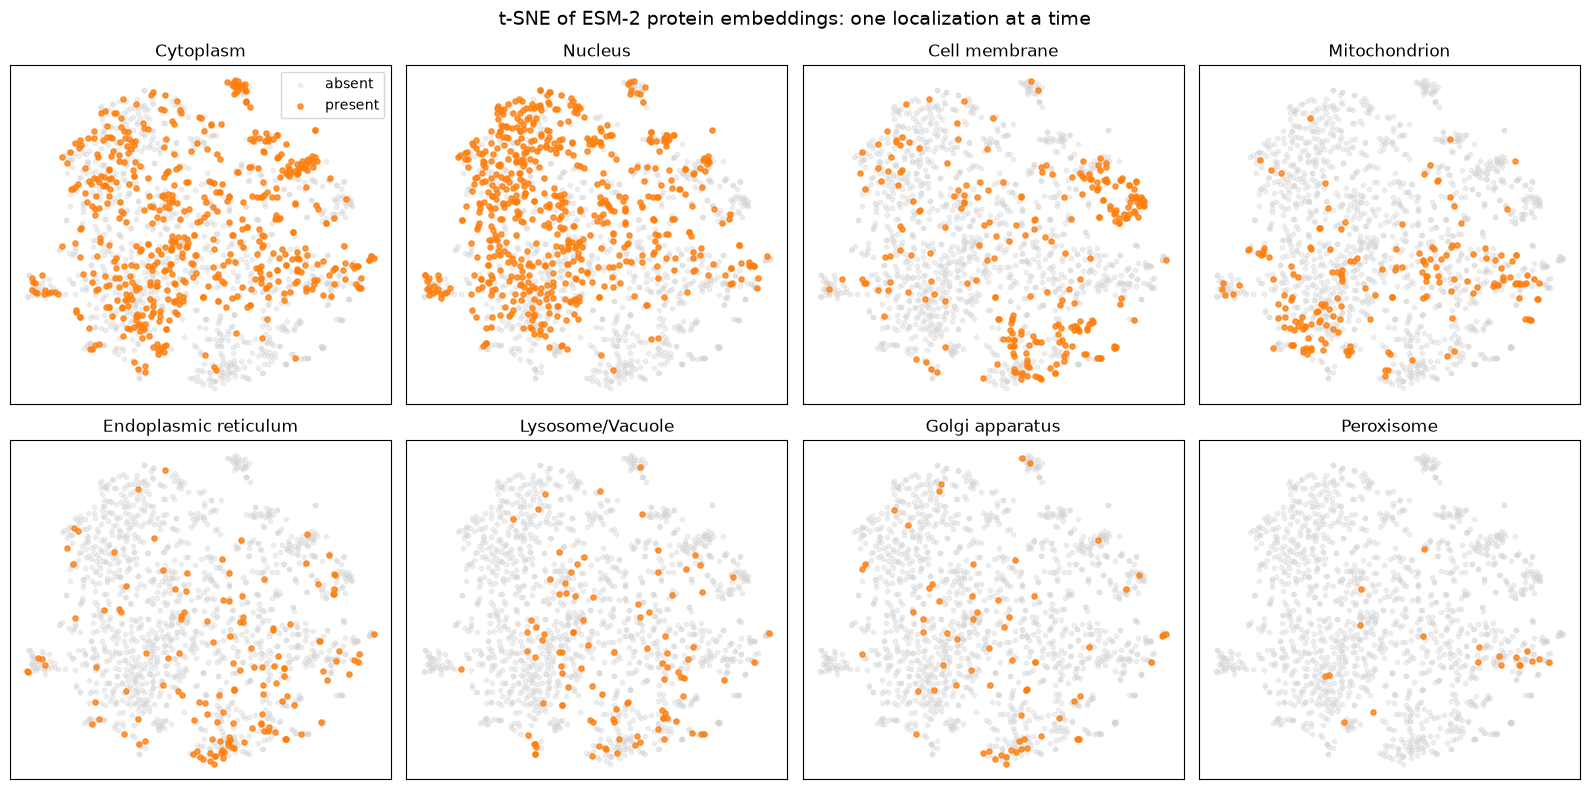

In [42]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

if embeddings_df is None:
    print('Run the ESM embedding cell first.')
else:
    # A reproducible subset keeps t-SNE interactive in the practical.
    max_points = min(1500, len(embeddings_df))
    embedding_sample = embeddings_df.sample(max_points, random_state=RANDOM_STATE).reset_index(drop=True)
    X_sample = embedding_sample[feature_cols].to_numpy(dtype=np.float32)
    n_pca = min(50, X_sample.shape[1], X_sample.shape[0] - 1)
    X_reduced = PCA(n_components=n_pca, random_state=RANDOM_STATE).fit_transform(X_sample)
    embedding_2d = TSNE(
        n_components=2, perplexity=30, init='pca', learning_rate='auto',
        max_iter=750, random_state=RANDOM_STATE
    ).fit_transform(X_reduced)

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for label, ax in zip(label_columns, axes.ravel()):
        positive = embedding_sample[label].to_numpy(dtype=bool)
        ax.scatter(embedding_2d[~positive, 0], embedding_2d[~positive, 1],
                   s=10, c='lightgray', alpha=0.35, label='absent')
        ax.scatter(embedding_2d[positive, 0], embedding_2d[positive, 1],
                   s=14, c='tab:orange', alpha=0.8, label='present')
        ax.set_title(label)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[0, 0].legend(loc='best', frameon=True)
    fig.suptitle('t-SNE of ESM-2 protein embeddings: one localization at a time', fontsize=14)
    plt.tight_layout()
    plt.show()

Linear probe HPA test macro-F1: 0.299


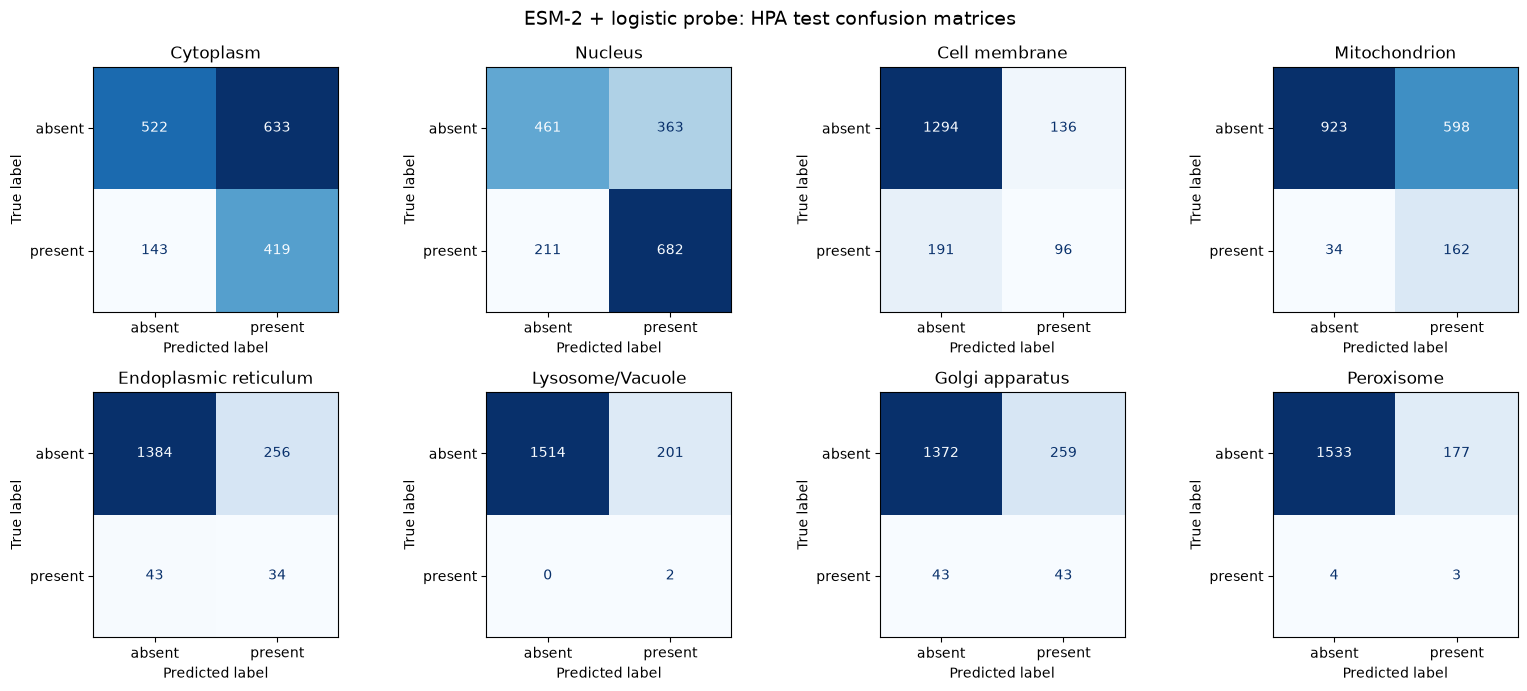

ESM-2 + MLP HPA test macro-F1: 0.0


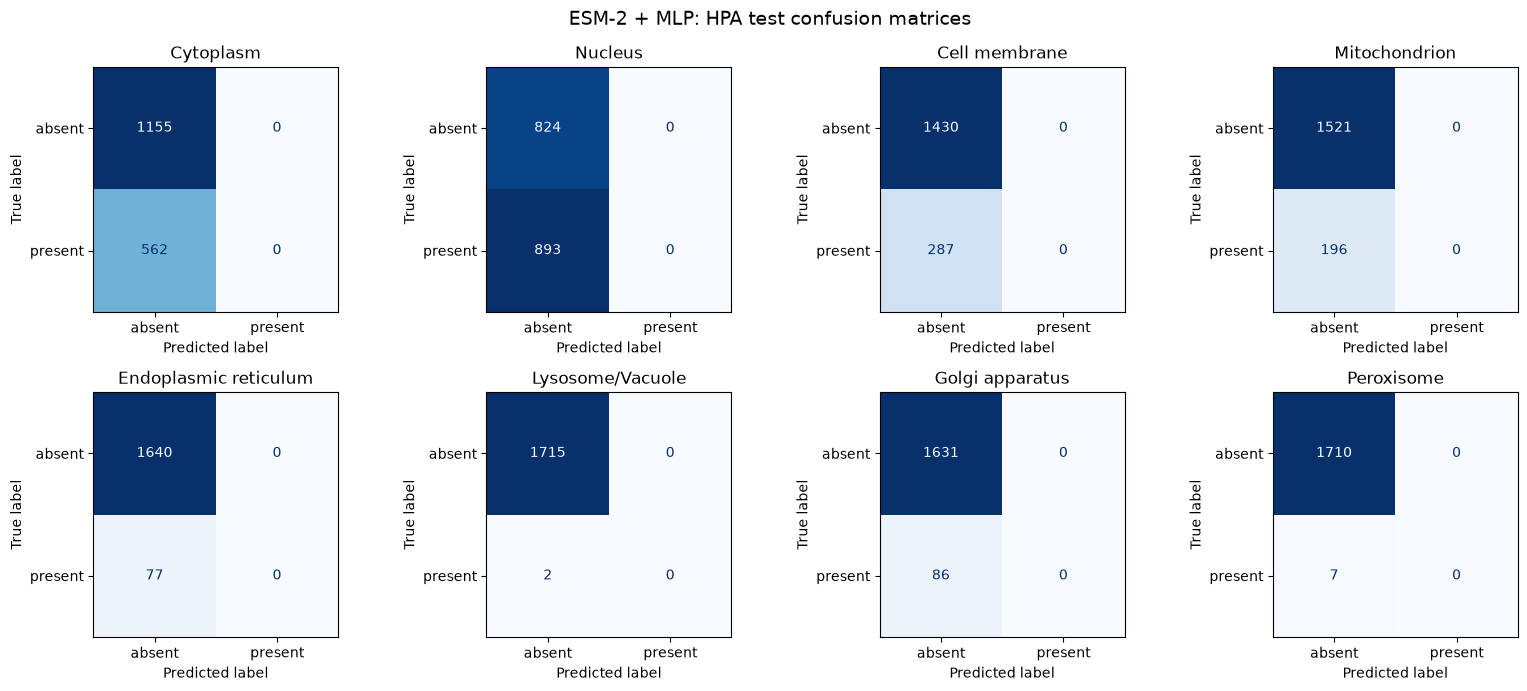

In [46]:

linear_test_predictions = linear_probe.predict(X_test)
print('Linear probe HPA test macro-F1:', round(f1_score(y_test, linear_test_predictions, average='macro', zero_division=0), 3))
plot_multilabel_confusions(y_test, linear_test_predictions, 'ESM-2 + logistic probe')

mlp.eval()
with torch.inference_mode():
    mlp_test_logits = mlp(torch.tensor(X_test, dtype=torch.float32, device=DEVICE)).cpu().numpy()
mlp_test_predictions = (1 / (1 + np.exp(-mlp_test_logits)) >= 0.5).astype(int)
print('ESM-2 + MLP HPA test macro-F1:', round(f1_score(y_test, mlp_test_predictions, average='macro', zero_division=0), 3))
plot_multilabel_confusions(y_test, mlp_test_predictions, 'ESM-2 + MLP')

## 15. Frozen embedding + small MLP

Optional comparison:

\[
\text{ESM embedding}

\rightarrow
\text{MLP}

\rightarrow
\text{localization}
\]

This tests whether a nonlinear predictor improves over the linear probe.

In [44]:
class EmbeddingMLP(nn.Module):
    def __init__(self, input_dim, n_classes):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, n_classes)
        )

    def forward(self, x):
        return self.net(x)

In [45]:
if embeddings_df is None:
    print('Run the embedding and logistic-probe cells first.')
else:
    mlp = EmbeddingMLP(X_train.shape[1], len(label_columns)).to(DEVICE)
    mlp_optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3)
    mlp_loss = nn.BCEWithLogitsLoss()
    X_tensor = torch.tensor(X_train, dtype=torch.float32, device=DEVICE)
    y_tensor = torch.tensor(y_train, dtype=torch.float32, device=DEVICE)
    for epoch in range(5):
        mlp.train()
        mlp_optimizer.zero_grad()
        loss = mlp_loss(mlp(X_tensor), y_tensor)
        loss.backward()
        mlp_optimizer.step()
    mlp.eval()
    with torch.no_grad():
        val_logits = mlp(torch.tensor(X_val, dtype=torch.float32, device=DEVICE)).cpu().numpy()
    print('Frozen-embedding MLP validation macro-F1:', round(multilabel_metrics(y_val, val_logits)['macro_f1'], 3))

Frozen-embedding MLP validation macro-F1: 0.0


In [47]:
val_logits

array([[-0.20413785, -0.1491229 , -0.24680799, ..., -0.24206348,
        -0.31140506, -0.32418126],
       [-0.20616472, -0.14772075, -0.24723239, ..., -0.24216932,
        -0.31044424, -0.31957543],
       [-0.1940963 , -0.263601  , -0.25785744, ..., -0.20832676,
        -0.34577295, -0.33840418],
       ...,
       [-0.22394538, -0.21995401, -0.28304595, ..., -0.2414697 ,
        -0.3592658 , -0.36933476],
       [-0.22223349, -0.21937889, -0.2827822 , ..., -0.24163689,
        -0.35789844, -0.36945224],
       [-0.21075504, -0.24516441, -0.24870807, ..., -0.25968528,
        -0.34138358, -0.37132117]], shape=(4719, 8), dtype=float32)

# Part XI — Compare from-scratch learning with pretrained representations

At this point the core comparison is:

| Representation | Predictor | Where representation was learned |
|---|---|---|
| amino-acid embedding | RNN | current labeled dataset |
| amino-acid embedding | LSTM | current labeled dataset |
| ESM-2 contextual embedding | Logistic Regression | large-scale pretraining |
| ESM-2 contextual embedding | MLP | large-scale pretraining |

Questions:

- Does pretrained representation improve macro-F1?
- Which classes gain most?
- Does the LSTM need more epochs?
- How does training time compare?
- How much labeled data was needed for each approach?

# Part XII — GPU server workflow

The next section should **not** be run on every student's laptop.

The goal is to learn a realistic remote-training workflow on the course GPU server. The commands below use the SSH alias `vcc-server-kse` from the instructor's local SSH configuration.

## Suggested server workflow

```text
local machine
    ↓
SSH
    ↓
GPU server
    ↓
activate environment
    ↓
check GPU
    ↓
launch training script
    ↓
save checkpoint + metrics
    ↓
copy results back
```

## 15. Connect to `vcc-server-kse`

Run in a terminal, not inside this notebook:

```bash
ssh vcc-server-kse
```

Check GPU visibility:

```bash
nvidia-smi
```

The recommended environment is a project-local `uv` environment. Detailed first-time setup is provided in `WEEK8_GPU_SERVER_SETUP.md`.

After setup, work from the project directory:

```bash
cd ~/kse-week8
source .venv/bin/activate
uv run --python .venv/bin/python -c "import torch; print(torch.cuda.is_available())"
```

## 16. Use `tmux`

A training job should survive an SSH disconnect.

```bash
tmux new -s esm_training
```

Detach:

```text
Ctrl+B, then D
```

Reconnect:

```bash
tmux attach -t esm_training
```

# Part XIII — Fine-tuning a pretrained ESM-2 model on the server

The server script uses ESM-2 as a sequence encoder, pools the contextual residue representations into one protein vector and sends that vector to an eight-output multilabel classification head. The `--num-unfrozen-layers` argument controls which pretrained weights receive updates.

Recommended server checkpoint:

```text
facebook/esm2_t12_35M_UR50D
```

Possible experiments:

### A. Frozen backbone
Train only the classification head.

### B. Partial fine-tuning
Unfreeze only the last Transformer block(s).

### C. Full fine-tuning
Update the whole small ESM-2 model.

For the practical, start with A. Move to B only after the frozen-head smoke test completes successfully. The supplied `train_esm.py` supports all three modes.

## 17. Server-side training configuration

The explicit trainability parameter is `--num-unfrozen-layers`: use `0` for a frozen backbone, a positive number such as `2` to unfreeze the last two Transformer blocks, and `-1` for full fine-tuning. The older `--mode frozen|partial|full` option remains available as a shortcut.

A config file keeps the training job reproducible.

Example:

```yaml
data_path: data/Swissprot_Train_Validation_dataset.csv
hpa_path: data/hpa_testset.csv
model_name: facebook/esm2_t12_35M_UR50D
max_length: 400
batch_size: 8
epochs: 5
learning_rate: 0.001  # frozen head; use 2e-5 for partial/full
mode: frozen
num_unfrozen_layers: 0  # 0=frozen, N=last N blocks, -1=full
output_dir: outputs/esm35m_frozen
```

## 18. Minimal fine-tuning architecture

\[
\text{ESM-2}

\rightarrow
\text{pooled protein representation}

\rightarrow
\text{linear multi-label classification head}
\]

A reusable implementation is given below.

In [ ]:

class ProteinFoundationClassifier(nn.Module):
    def __init__(self, backbone, hidden_dim, n_labels):
        super().__init__()

        self.backbone = backbone
        self.classifier = nn.Linear(hidden_dim, n_labels)

    def forward(self, input_ids, attention_mask):
        output = self.backbone(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        pooled = masked_mean_pool(
            output.last_hidden_state,
            attention_mask
        )

        return self.classifier(pooled)

## 19. Freeze / unfreeze helpers

In [42]:
def freeze_all(model):
    for p in model.parameters():
        p.requires_grad = False


def unfreeze_all(model):
    for p in model.parameters():
        p.requires_grad = True

Partial fine-tuning is model-architecture dependent.

For ESM-style Transformers, the exact module path for encoder layers should be inspected before selecting the last \(N\) blocks.

Do **not** blindly unfreeze layers by name without checking the model structure:

```python
print(model)
```

# Part XIV — `train_esm.py`

The checked-in `train_esm.py` is the reproducible server training script. It uses the same eight-label target, partition split and HPA external test set as the local sections.

The legacy string below is retained only as a discussion reference and is deliberately not written over the checked-in script.

In [44]:
TRAIN_SCRIPT_PATH = DATA_DIR / 'train_esm.py'
print('Server script:', TRAIN_SCRIPT_PATH)
print('Copy this script together with both CSV files before launching the remote job.')

Server script: train_esm.py
Copy this script together with both CSV files before launching the remote job.


## 20. Upload required files to the server

From the local terminal, create the remote project directory and copy only the script and data:

```bash
ssh vcc-server-kse 'mkdir -p ~/kse-week8/data ~/kse-week8/outputs'
scp kse-github/practicals/week8/train_esm.py vcc-server-kse:~/kse-week8/
scp kse-github/practicals/week8/Swissprot_Train_Validation_dataset.csv vcc-server-kse:~/kse-week8/data/
scp kse-github/practicals/week8/hpa_testset.csv vcc-server-kse:~/kse-week8/data/
```



## 21. Launch training

On the server, after following `WEEK8_GPU_SERVER_SETUP.md`:

```bash
uv run --python .venv/bin/python train_esm.py \
  --data-path data/Swissprot_Train_Validation_dataset.csv \
  --hpa-path data/hpa_testset.csv \
  --mode frozen \
  --output-dir outputs/esm35m_frozen
```

The same script can be controlled directly by layer count:

```bash
# partial fine-tuning: head + last two Transformer blocks
uv run --python .venv/bin/python train_esm.py --data-path data/Swissprot_Train_Validation_dataset.csv --hpa-path data/hpa_testset.csv --num-unfrozen-layers 2 --learning-rate 2e-5 --output-dir outputs/esm35m_partial

# full fine-tuning
uv run --python .venv/bin/python train_esm.py --data-path data/Swissprot_Train_Validation_dataset.csv --hpa-path data/hpa_testset.csv --num-unfrozen-layers -1 --learning-rate 2e-5 --batch-size 2 --output-dir outputs/esm35m_full
```

or inside `tmux`:

```bash
tmux new -s esm
uv run --python .venv/bin/python train_esm.py --data-path data/Swissprot_Train_Validation_dataset.csv --hpa-path data/hpa_testset.csv --mode frozen --output-dir outputs/esm35m_frozen
```

Monitor GPU memory / utilization from another terminal:

```bash
watch -n 1 nvidia-smi
```

# Part XV — Bring results back

Copy the metrics locally:

```bash
scp vcc-server-kse:~/kse-week8/outputs/esm35m_frozen/history.csv .
```

Optionally copy the checkpoint:

```bash
scp vcc-server-kse:~/kse-week8/outputs/esm35m_frozen/best_model.pt .
```

,epoch,seconds,train_macro_f1,train_micro_f1,train_exact_match,train_loss,val_macro_f1,val_micro_f1,val_exact_match,val_loss
0,1,103.821263,0.393233,0.476227,0.115841,0.956298,0.419375,0.500260,0.120576,0.809901
1,2,103.858488,0.427481,0.517334,0.152679,0.859554,0.429277,0.547213,0.179063,0.763292
2,3,104.196515,0.437711,0.530854,0.169424,0.830260,0.427333,0.525045,0.183513,0.749762
3,4,102.423534,0.444289,0.537514,0.176629,0.811475,0.433321,0.541372,0.204492,0.738915
4,5,104.358659,0.448094,0.542854,0.185813,0.798758,0.427974,0.526952,0.203009,0.736195


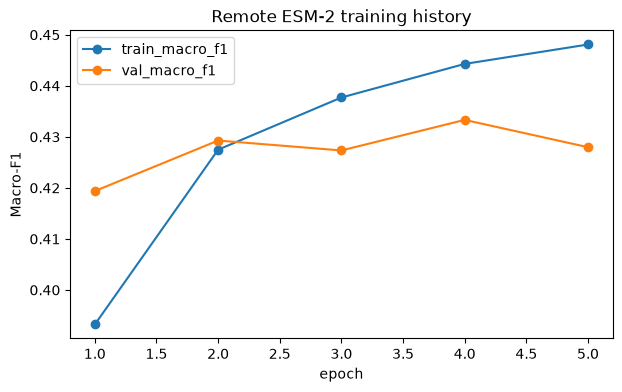

In [49]:
SERVER_HISTORY_PATH = Path('C:/Users/user\Desktop\kse\practicals\kse-github\practicals\history.csv')
if SERVER_HISTORY_PATH.exists():
    server_history = pd.read_csv(SERVER_HISTORY_PATH)
    display(server_history)
    server_history.plot(x='epoch', y=['train_macro_f1', 'val_macro_f1'], marker='o', figsize=(7, 4))
    plt.ylabel('Macro-F1')
    plt.title('Remote ESM-2 training history')
    plt.show()
else:
    print('Copy outputs/esm35m_frozen/history.csv here before plotting.')

# Part XVI — Fine-tuning experiments

Fine-tuning changes which parameters receive gradient updates. The classification head is always trained, while the pretrained ESM-2 backbone can be frozen completely, partially unfrozen, or trained end-to-end.

For a parameter \(\theta\), the optimizer updates it only when `requires_grad=True`:

$$
\theta \leftarrow \theta - \eta \nabla_{\theta} \mathcal{L}
$$

Here \(\eta\) is the learning rate and \(\mathcal{L}\) is the multilabel BCE-with-logits loss. Freezing a layer means that its weights participate in the forward pass but are not changed by the optimizer.

Recommended experiments:

### A. Frozen backbone — `num_unfrozen_layers=0`
Train only the new localization head. This is the cheapest experiment and tests the quality of the pretrained representation.

### B. Partial fine-tuning — `num_unfrozen_layers=2`
Train the classification head and the last two Transformer blocks. This allows task-specific adaptation while keeping most pretrained weights fixed.

### C. Full fine-tuning — `num_unfrozen_layers=-1`
Train the complete ESM-2 backbone and the classification head. This has the highest memory and overfitting risk.

Compare:

- trainable parameter count;
- GPU memory use;
- training time;
- validation macro-F1;
- HPA test macro-F1, evaluated only after model selection;
- the gap between training and validation performance.

Do not compare only accuracy.

In [50]:
def find_transformer_blocks(backbone):
    """Return the Transformer block list used by an ESM-style backbone."""
    candidates = [
        ('encoder.layer', getattr(getattr(backbone, 'encoder', None), 'layer', None)),
        ('esm.encoder.layer', getattr(getattr(getattr(backbone, 'esm', None), 'encoder', None), 'layer', None)),
        ('transformer.layer', getattr(getattr(backbone, 'transformer', None), 'layer', None)),
    ]
    for name, blocks in candidates:
        if blocks is not None and len(blocks) > 0:
            return name, blocks
    raise AttributeError('Could not find Transformer blocks. Inspect print(backbone).')

def configure_trainability(model, num_unfrozen_layers):
    """Configure an ESM classifier: 0=frozen, N=last N blocks, -1=full."""
    for parameter in model.backbone.parameters():
        parameter.requires_grad = False
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True

    if num_unfrozen_layers == -1:
        for parameter in model.backbone.parameters():
            parameter.requires_grad = True
        selected = 'all Transformer blocks'
    elif num_unfrozen_layers == 0:
        selected = 'no Transformer blocks'
    elif num_unfrozen_layers > 0:
        path, blocks = find_transformer_blocks(model.backbone)
        if num_unfrozen_layers > len(blocks):
            raise ValueError(f'Requested {num_unfrozen_layers} blocks, but the model has {len(blocks)}.')
        for block in blocks[-num_unfrozen_layers:]:
            for parameter in block.parameters():
                parameter.requires_grad = True
        selected = f'last {num_unfrozen_layers} blocks via {path}'
    else:
        raise ValueError('Use -1 for full fine-tuning or a non-negative number of blocks.')

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f'{selected}; trainable parameters: {trainable:,} / {total:,} ({100 * trainable / total:.2f}%)')
    return model

# Examples after constructing a ProteinFoundationClassifier named `model`:
# configure_trainability(model, 0)   # frozen backbone + trainable head
# configure_trainability(model, 2)   # head + last two Transformer blocks
# configure_trainability(model, -1)  # full fine-tuning

print('Helper ready. Apply it after constructing the ESM classifier.')

Helper ready. Apply it after constructing the ESM classifier.


### Results table

| Model | Trainable params | Device | Val macro-F1 | Test macro-F1 | Time/epoch | Peak GPU memory |
|---|---:|---|---:|---:|---:|---:|
| RNN | | local | | | | |
| LSTM | | local | | | | |
| BiLSTM | | local | | | | |
| Frozen ESM embedding + LR | | local | | | | |
| Frozen ESM-35M + head | | server | | | | |
| Partial ESM-35M fine-tune | | server | | | | |
| Full ESM-35M fine-tune | | server | | | | |

# Part XVII — PEFT / LoRA extension

This should be treated as an advanced task.

Conceptually:

\[
W' = W + \Delta W
\]

with:

\[
\Delta W = AB
\]

where \(A\) and \(B\) are much smaller trainable matrices.

Questions:

- How many parameters are actually trained?
- How much GPU memory is saved?
- Does validation performance remain competitive?

In [46]:
# Optional skeleton

# from peft import LoraConfig, get_peft_model

# lora_config = LoraConfig(
#     r=8,
#     lora_alpha=16,
#     lora_dropout=0.1,
#     target_modules=[...]
# )

# peft_model = get_peft_model(model, lora_config)

# peft_model.print_trainable_parameters()

# Part XVIII — Biological and methodological interpretation

## Questions

1. Did the LSTM outperform the basic RNN?
2. Did bidirectionality help?
3. How sensitive were recurrent models to maximum sequence length?
4. How did frozen ESM embeddings compare with the recurrent models?
5. Did fine-tuning improve over frozen embeddings?
6. Was the improvement worth the computational cost?
7. Which localization classes remained difficult?
8. Could class imbalance explain some failures?
9. Why would a random protein split likely produce a more optimistic score?
10. What biological information may already be encoded in a pretrained protein model?
11. What information is still specific to the downstream localization labels?
12. When would a small LSTM still be preferable to a foundation model?

# Homework — sequence models and ESM-2

## Objective

Investigate the trade-off between model size, amount of fine-tuning, predictive performance and computational cost for protein subcellular-localization prediction. The task remains **multi-label classification** with the eight localization labels used in this practical.

> **Evaluation rule:** use the SwissProt training/validation partitions for model development. Keep `hpa_testset.csv` untouched until the final evaluation. Do not tune hyperparameters or thresholds on HPA.

## Part A — Reproduce and document a baseline

1. Re-run either the LSTM or BiLSTM baseline.
2. Re-run the local ESM-2 8M frozen-embedding logistic probe.
3. Record the random seed, maximum sequence length, batch size, number of epochs and decision threshold.
4. Report validation and HPA test **macro-F1**, **micro-F1** and exact-match accuracy.

Answer:

- Which metric is most informative for this imbalanced multi-label problem, and why?
- Which localization labels are easiest and hardest for the baseline?
- Does the model tend to miss labels or produce false positive labels?

## Part B — Data-efficiency experiment

Train the same downstream model using 10%, 50% and 100% of the SwissProt training data. Use the same validation set, test set, architecture, preprocessing and random seed policy for every fraction.

Create a plot of validation macro-F1 against the number of training proteins. Add the HPA test score for the final selected model only.

Answer:

- At which training fraction do the performance gains begin to level off?
- Does the data-efficient model generalize to HPA in the same way as it performs on validation?
- What does this suggest about the value of additional labeled proteins?

## Part C — Frozen versus fine-tuned ESM-2

On the GPU server, compare the following experiments with the same data split and evaluation procedure:

1. Frozen ESM-2 35M with a trainable classification head.
2. Partial fine-tuning: unfreeze the last two Transformer blocks.
3. Full fine-tuning of ESM-2 35M.

If you will have enough machine time try ESM-2 - 150M.

Start with a one-epoch smoke test. Run the three experiments sequentially, in separate `tmux` sessions or with separate output directories. Use a smaller batch size or maximum sequence length if GPU memory is insufficient.

For each run, record:

- trainable parameter count;
- validation and HPA test macro-F1;
- micro-F1 and exact-match accuracy;
- training time per epoch;
- peak GPU memory;
- the best validation epoch;
- whether training and validation curves indicate overfitting.

Use this table in the report:

| Model | Training mode | Trainable parameters | Max length | Batch size | Val macro-F1 | HPA macro-F1 | Time/epoch | Peak GPU memory |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| LSTM or BiLSTM | from scratch | | | | | | | |
| ESM-2 8M + logistic probe | frozen embeddings | | | | | | | |
| ESM-2 35M + head | frozen | | | | | | | |
| ESM-2 35M | partial | | | | | | | |
| ESM-2 35M | full | | | | | | | |

Answer:

- Does fine-tuning improve over a frozen backbone?
- Is the improvement large enough to justify the additional compute?
- Which model has the best validation-to-HPA generalization?
- Which classes benefit from fine-tuning, and which remain difficult?
- What evidence of overfitting can you see in the learning curves?

